# CS-317: Reinforcement Learning — Lab 11
## Q-learning: Learning the Best Behaviour Without the Rules
**BS AI-1**  
**Muhammad Sikandar Hussain (502808)**

This notebook provides the charging-room environment and helper functions. Complete every `# TODO` cell, run all cells top to bottom without errors, and answer the written questions in the markdown cells provided for them.

- Set your personal **SEED** (the last three digits of your roll number) in the first code cell below. Every random experiment must use it, and your written answers must refer to your own numbers.
- **Predict first** cells must be filled in *before* you run the code beneath them.
- `room_rules` is the room's rule book. It may be used **only** by value iteration in Task 2. Q-learning must learn only through `env.reset()` and `env.step()` (Task 3) or from a recorded log (Task 4).

Reinforcement-learning libraries may not be used. NumPy and Matplotlib only.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)

In [2]:
# ---------------------------------------------------------------
# Personal seed: the last three digits of your roll number.
# Every random experiment in this notebook must use it.
# ---------------------------------------------------------------
SEED = 808          # Roll number 502808 -> last three digits: 808

assert SEED is not None, "Set SEED to the last three digits of your roll number before running the notebook."
print("SEED =", SEED)

SEED = 808


---
## Provided Starter Code

Run the cell in this section as-is. You do not need to modify it.

| Name | What it gives you |
|---|---|
| `RoomEnv()` | the charging room: `reset()` → `s` ; `step(a)` → `s2, r, done` (rules hidden) |
| `GAMMA` | the discount, 0.9 |
| `room_rules(s, a)` | the rule book → `s2, r, done` (**value iteration in Task 2 only**) |
| `record_log(env, n_episodes, rng)` | another robot moves at random and records every step `(s, a, r, s2, done)` |
| `epsilon_greedy(Q, s, epsilon, rng)` | ε-greedy action choice, as in Lab 9 |
| `test_route(env, Q)` | follows the best action of `Q` from the start, no exploration → `steps, path, reached` |
| `plot_room(Q, title, path)` | draws the room with the best action in every cell that has learned something, and the route shaded |
| `plot_row_values(Qs, labels, V_ref, title)` | bar plot of max Q along the start row (cells 20–28) against reference values |
| `value_gap(Q, V_ref)` | average distance between max Q and `V_ref` over all cells |

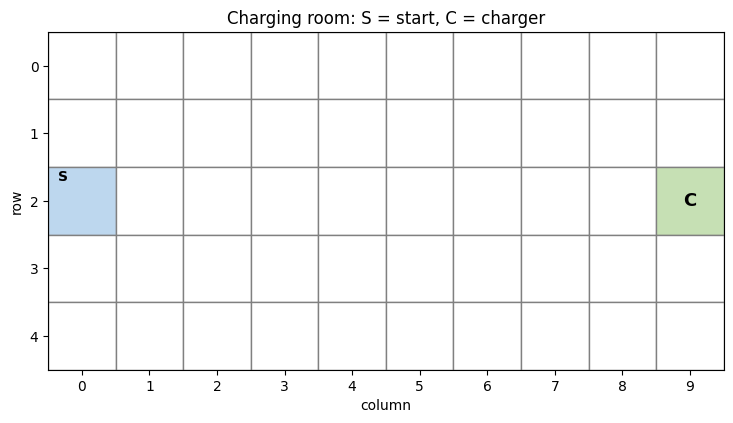

In [3]:
# ---------------------------------------------------------------
# The charging room (used in every task)
#
#   A 5 x 10 room, cells numbered row by row: cell = 10 * row + col.
#   The robot starts at S (row 2, col 0 = cell 20) and must find the
#   charger C (row 2, col 9 = cell 29).
#   Actions: 0 = Up, 1 = Down, 2 = Left, 3 = Right. A move into a wall
#   leaves the robot in place. Reward: +1 for reaching C, 0 otherwise.
#   Reaching C ends the episode. Discount gamma = 0.9.
#   RoomEnv() hides the rules. room_rules() is the rule book, given
#   ONLY for value iteration in Task 2.
# ---------------------------------------------------------------

ROOM_ROWS, ROOM_COLS = 5, 10
ROOM_N, ROOM_ACTIONS = ROOM_ROWS * ROOM_COLS, 4
ROOM_START, ROOM_GOAL = 20, 29
GAMMA = 0.9
ACTION_NAMES = ["Up", "Down", "Left", "Right"]


class RoomEnv:
    """The charging room as an environment you can only ACT in.

    reset()       -> s                 the start cell (20)
    step(action)  -> s2, r, done       next cell, reward, end-of-episode flag
    The rules are hidden: reading env.P or env.R raises an error.
    """

    def __init__(self):
        self.__s = None

    def __getattr__(self, name):
        if name in ("P", "R", "transition_matrix"):
            raise AttributeError(f"The model is hidden: '{name}' is not available. "
                                 "This environment only offers reset() and step(action).")
        raise AttributeError(name)

    def reset(self):
        self.__s = ROOM_START
        return self.__s

    def step(self, action):
        if self.__s is None or self.__s == ROOM_GOAL:
            raise RuntimeError("Episode has ended (or not started): call reset() first.")
        r, c = divmod(self.__s, ROOM_COLS)
        if action == 0:   r = max(r - 1, 0)
        elif action == 1: r = min(r + 1, ROOM_ROWS - 1)
        elif action == 2: c = max(c - 1, 0)
        else:             c = min(c + 1, ROOM_COLS - 1)
        self.__s = r * ROOM_COLS + c
        return self.__s, (1.0 if self.__s == ROOM_GOAL else 0.0), self.__s == ROOM_GOAL


def room_rules(s, a):
    """The RULE BOOK of the room, for value iteration (Task 2) ONLY.
    Returns (s2, r, done) for taking action a in cell s. Q-learning must not use it."""
    r, c = divmod(s, ROOM_COLS)
    if a == 0:   r = max(r - 1, 0)
    elif a == 1: r = min(r + 1, ROOM_ROWS - 1)
    elif a == 2: c = max(c - 1, 0)
    else:        c = min(c + 1, ROOM_COLS - 1)
    s2 = r * ROOM_COLS + c
    return s2, (1.0 if s2 == ROOM_GOAL else 0.0), s2 == ROOM_GOAL


def record_log(env, n_episodes, rng):
    """Another robot explores the room by choosing EVERY move at random, and writes down
    everything that happens. Returns a list of steps (s, a, r, s2, done)."""
    log = []
    for _ in range(n_episodes):
        s = env.reset()
        done = False
        while not done:
            a = int(rng.integers(ROOM_ACTIONS))
            s2, r, done = env.step(a)
            log.append((s, a, r, s2, done))
            s = s2
    return log


def epsilon_greedy(Q, s, epsilon, rng):
    """As in Lab 9: a random action with probability epsilon, otherwise a best action
    of Q[s] (ties broken at random)."""
    if rng.random() < epsilon:
        return int(rng.integers(Q.shape[1]))
    return int(rng.choice(np.flatnonzero(Q[s] == Q[s].max())))


def test_route(env, Q, max_steps=100):
    """Follows the BEST action of Q in every cell (no exploration) from the start.
    Returns (steps, path, reached): the number of moves, the list of cells visited,
    and whether the charger was reached within max_steps."""
    s = env.reset()
    path = [s]
    for t in range(max_steps):
        s, r, done = env.step(int(np.argmax(Q[s])))
        path.append(s)
        if done:
            return t + 1, path, True
    return max_steps, path, False


def plot_room(Q, title="", path=None):
    """Draws the room. In every cell where the robot has learned something (max Q > 0),
    an arrow shows its current best action. If a path is given (from test_route), the
    cells on it are shaded yellow."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    on_path = set(path) if path is not None else set()
    for s in range(ROOM_N):
        r, c = divmod(s, ROOM_COLS)
        face = "#c6e0b4" if s == ROOM_GOAL else ("#fff2cc" if s in on_path else ("#bdd7ee" if s == ROOM_START else "white"))
        ax.add_patch(plt.Rectangle((c - .5, r - .5), 1, 1, facecolor=face, edgecolor="grey"))
        if s == ROOM_GOAL:
            ax.text(c, r, "C", ha="center", va="center", fontsize=13, fontweight="bold"); continue
        if s == ROOM_START:
            ax.text(c - .35, r - .3, "S", fontsize=10, fontweight="bold")
        if Q is not None and Q[s].max() > 0:
            a = int(np.argmax(Q[s]))
            dx, dy = [(0, -.3), (0, .3), (-.3, 0), (.3, 0)][a]
            ax.annotate("", xy=(c + dx, r + dy), xytext=(c, r),
                        arrowprops=dict(arrowstyle="->", color="crimson", lw=1.5))
    ax.set_xlim(-.5, ROOM_COLS - .5); ax.set_ylim(ROOM_ROWS - .5, -.5)
    ax.set_xticks(range(ROOM_COLS)); ax.set_yticks(range(ROOM_ROWS))
    ax.set_xlabel("column"); ax.set_ylabel("row"); ax.set_aspect("equal")
    ax.set_title(title); plt.tight_layout(); plt.show()


def plot_row_values(Qs, labels, V_ref, title=""):
    """Bar plot of max_a Q(s, a) along the start row (cells 20 to 28) for one or more
    Q tables, with the reference values V_ref (e.g. your V* from Task 2) as a dashed line."""
    w = 0.8 / len(Qs)
    fig, ax = plt.subplots(figsize=(8, 3.4))
    for i, (Q, lab) in enumerate(zip(Qs, labels)):
        ax.bar(np.arange(9) - 0.4 + w / 2 + i * w, np.asarray(Q).max(axis=1)[20:29], w, label=lab)
    ax.plot(np.arange(9), np.asarray(V_ref)[20:29], "k--", marker="o", label="V* (value iteration)")
    ax.set_xticks(np.arange(9)); ax.set_xticklabels(range(20, 29))
    ax.set_xlabel("cell (start row)"); ax.set_ylabel("max Q(cell, a)")
    ax.set_title(title); ax.legend(fontsize=8); plt.tight_layout(); plt.show()


def value_gap(Q, V_ref):
    """Average distance between max_a Q(s, a) and V_ref(s) over all 49 non-charger cells."""
    mask = np.arange(ROOM_N) != ROOM_GOAL
    return float(np.abs(np.asarray(Q).max(axis=1) - np.asarray(V_ref))[mask].mean())


plot_room(None, title="Charging room: S = start, C = charger")

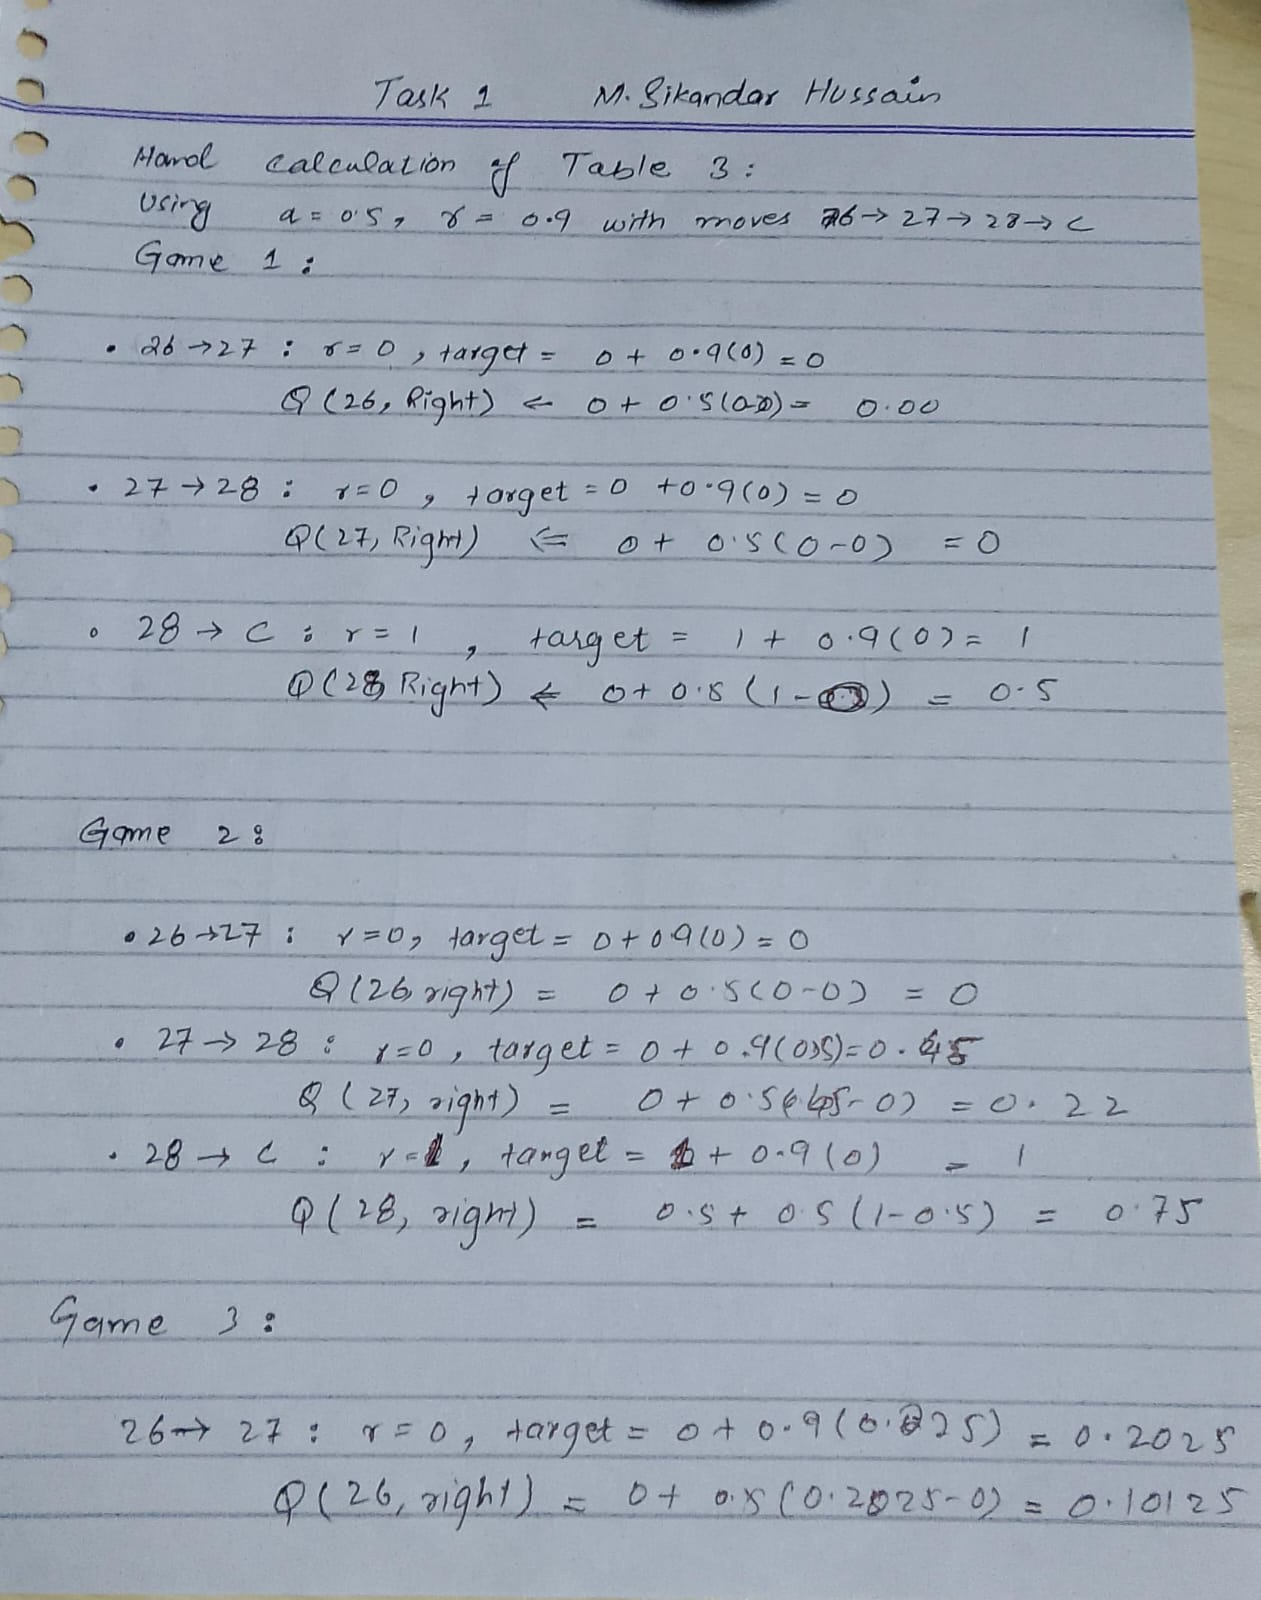

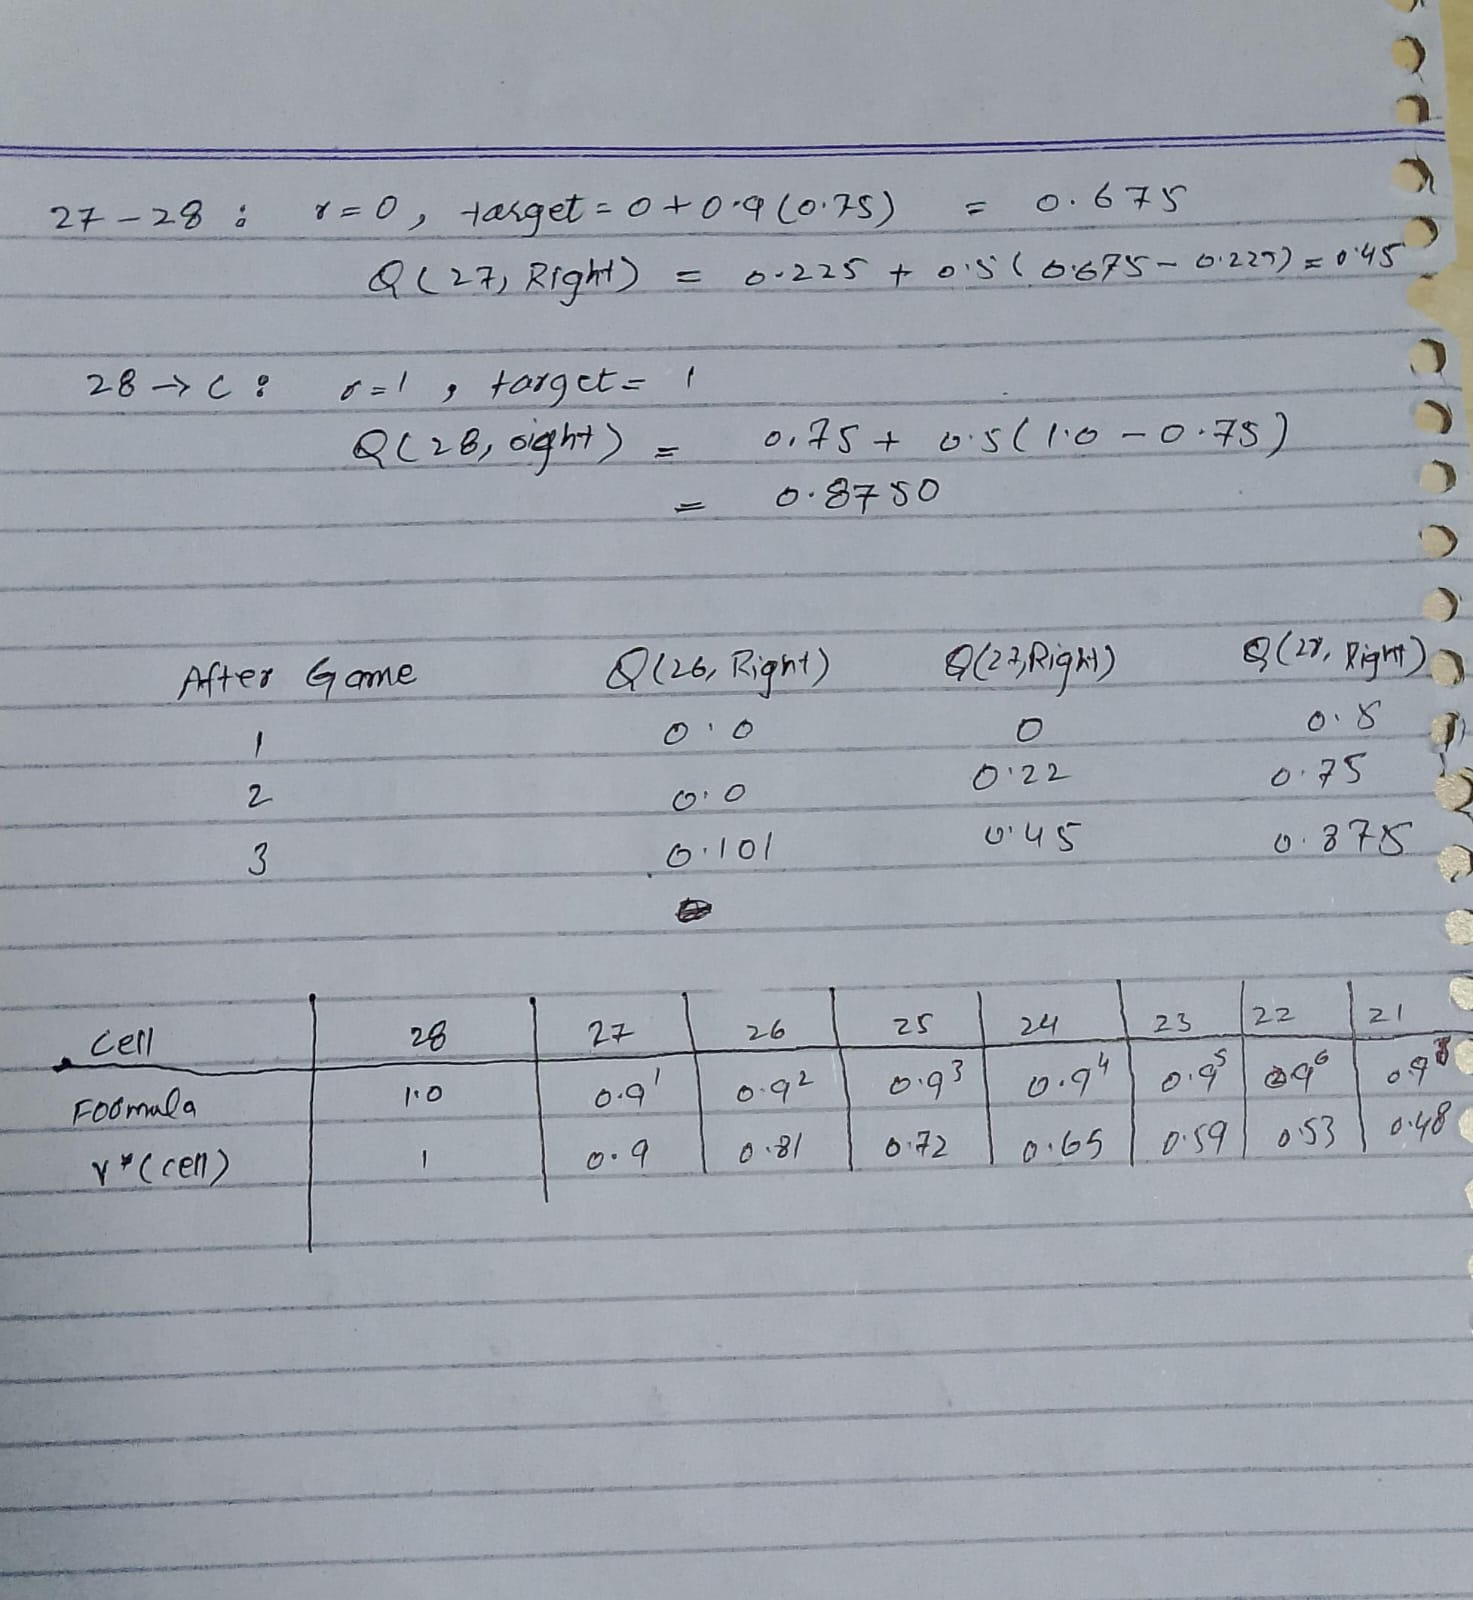

---
## Part 1: The Q-learning Update and the Bellman Optimality Equation

Q-learning moves each score towards a target built from the **best** score in the next cell:

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\,[\,R_{t+1} + \gamma \max_{a} Q(S_{t+1}, a) - Q(S_t,A_t)\,]$$

When the move ends the episode, the target is just $R_{t+1}$. The target comes from the **Bellman optimality equation**, which says what the values of the *best* behaviour must satisfy:

$$Q^*(s,a) = r + \gamma \max_{a'} Q^*(s',a') \qquad\qquad V^*(s) = \max_a Q^*(s,a)$$

Because the target always uses the best next action, whatever the robot actually does next, Q-learning is **off-policy**: it learns about the best (greedy) behaviour while it behaves in some other way (for example ε-greedy, or even completely at random).

### Task 1: Q-learning by Hand

To keep the calculation short, the robot is placed in **cell 26** and plays three games. In every game it moves **Right, Right, Right**: 26 → 27 → 28 → C. The last move gives +1 and ends the game; the others give 0. All Q-values start at 0. Use α = 0.5 and γ = 0.9, and update in the order the moves happen.

**Predict first.** After the first game, which of the three scores Q(26, Right), Q(27, Right), Q(28, Right) will have changed?

**Prediction:**  
Only **$Q(28, \text{Right})$** will have changed after the first game. In game 1, all $Q$-values start at 0. The move from 26 to 27 gives $R=0$ and targets $\gamma \max_a Q(27, a) = 0$, so $Q(26, \text{Right})$ remains 0. The move from 27 to 28 gives $R=0$ and targets $\gamma \max_a Q(28, a) = 0$, so $Q(27, \text{Right})$ remains 0. Only the final move from 28 into the charger yields $R=+1$ and ends the episode, updating $Q(28, \text{Right})$ to $0 + 0.5(1 - 0) = 0.5$.

**(a)** Table 3: Q-values after each game

| After game | Q(26, Right) | Q(27, Right) | Q(28, Right) |
|---|---|---|---|
| 1 | **0.0000** | **0.0000** | **0.5000** |
| 2 | **0.0000** | **0.2250** | **0.7500** |
| 3 | **0.10125** | **0.4500** | **0.8750** |

*Detailed Hand Working:*
- **Initial:** All $Q(s, a) = 0$. $\alpha = 0.5, \gamma = 0.9$.
- **Game 1:**
  - $26 \to 27$: $r=0$, target $= 0 + 0.9 \max_a Q(27, a) = 0$.  
    $Q(26, \text{Right}) \leftarrow 0 + 0.5(0 - 0) = \mathbf{0.0}$.
  - $27 \to 28$: $r=0$, target $= 0 + 0.9 \max_a Q(28, a) = 0$.  
    $Q(27, \text{Right}) \leftarrow 0 + 0.5(0 - 0) = \mathbf{0.0}$.
  - $28 \to C$: $r=1$, terminal, target $= 1.0$.  
    $Q(28, \text{Right}) \leftarrow 0 + 0.5(1.0 - 0) = \mathbf{0.5}$.
- **Game 2:**
  - $26 \to 27$: $r=0$, target $= 0 + 0.9 \max_a Q(27, a) = 0 + 0.9(0) = 0$.  
    $Q(26, \text{Right}) \leftarrow 0 + 0.5(0 - 0) = \mathbf{0.0}$.
  - $27 \to 28$: $r=0$, target $= 0 + 0.9 \max_a Q(28, a) = 0.9(0.5) = 0.45$.  
    $Q(27, \text{Right}) \leftarrow 0 + 0.5(0.45 - 0) = \mathbf{0.225}$.
  - $28 \to C$: $r=1$, terminal, target $= 1.0$.  
    $Q(28, \text{Right}) \leftarrow 0.5 + 0.5(1.0 - 0.5) = 0.5 + 0.25 = \mathbf{0.75}$.
- **Game 3:**
  - $26 \to 27$: $r=0$, target $= 0 + 0.9 \max_a Q(27, a) = 0.9(0.225) = 0.2025$.  
    $Q(26, \text{Right}) \leftarrow 0 + 0.5(0.2025 - 0) = \mathbf{0.10125}$.
  - $27 \to 28$: $r=0$, target $= 0 + 0.9 \max_a Q(28, a) = 0.9(0.75) = 0.675$.  
    $Q(27, \text{Right}) \leftarrow 0.225 + 0.5(0.675 - 0.225) = 0.225 + 0.225 = \mathbf{0.450}$.
  - $28 \to C$: $r=1$, terminal, target $= 1.0$.  
    $Q(28, \text{Right}) \leftarrow 0.75 + 0.5(1.0 - 0.75) = 0.75 + 0.125 = \mathbf{0.875}$.

**(b)** Use the Bellman optimality equation to find the best possible values V\*(cell) along the start row, working backwards from the charger. (Moving Right from cell 28 reaches the charger: reward +1, and the episode ends.)

Table 4: best possible values along the start row

Working backwards: $V^*(s) = \max_a [r + \gamma V^*(s')]$.
- $V^*(28) = 1.0$ (immediate reward $+1$, done)
- $V^*(27) = 0 + 0.9 \times V^*(28) = 0.9 \times 1.0 = \mathbf{0.900}$
- $V^*(26) = 0.9 \times V^*(27) = 0.9^2 = \mathbf{0.810}$
- $V^*(25) = 0.9 \times V^*(26) = 0.9^3 = \mathbf{0.729}$
- $V^*(24) = 0.9 \times V^*(25) = 0.9^4 \approx \mathbf{0.656}$
- $V^*(23) = 0.9 \times V^*(24) = 0.9^5 \approx \mathbf{0.590}$
- $V^*(22) = 0.9 \times V^*(23) = 0.9^6 \approx \mathbf{0.531}$
- $V^*(21) = 0.9 \times V^*(22) = 0.9^7 \approx \mathbf{0.478}$
- $V^*(20) = 0.9 \times V^*(21) = 0.9^8 \approx \mathbf{0.430}$

| Cell | 28 | 27 | 26 | 25 | 24 | 23 | 22 | 21 | 20 (start) |
|---|---|---|---|---|---|---|---|---|---|
| V\*(cell) | **1.000** | **0.900** | **0.810** | **0.729** | **0.656** | **0.590** | **0.531** | **0.478** | **0.430** |

**(c)** Implement `q_update(Q, s, a, r, s2, done, alpha, gamma)`, which applies one Q-learning update. Replay the three games of part (a) with it and check Table 3. You will use `q_update` again in Tasks 3 and 4.

In [4]:
def q_update(Q, s, a, r, s2, done, alpha, gamma):
    # One Q-learning update of Q[s, a]:
    #   target = r                       if the move ended the episode
    #          = r + gamma * max(Q[s2])  otherwise
    #   Q[s, a] moves a fraction alpha of the way towards the target.
    target = r if done else r + gamma * np.max(Q[s2])
    Q[s, a] += alpha * (target - Q[s, a])


Q_hand = np.zeros((ROOM_N, ROOM_ACTIONS))
RIGHT = 3
# Replay the three games (26 -> 27 -> 28 -> C, all moves Right) with q_update,
# alpha = 0.5, gamma = 0.9, and print Q(26,Right), Q(27,Right), Q(28,Right) after each game.
for game in range(1, 4):
    q_update(Q_hand, 26, RIGHT, 0.0, 27, False, 0.5, 0.9)
    q_update(Q_hand, 27, RIGHT, 0.0, 28, False, 0.5, 0.9)
    q_update(Q_hand, 28, RIGHT, 1.0, 29, True, 0.5, 0.9)
    print(f"After game {game}: Q(26, Right) = {Q_hand[26, RIGHT]:.5f}, "
          f"Q(27, Right) = {Q_hand[27, RIGHT]:.5f}, "
          f"Q(28, Right) = {Q_hand[28, RIGHT]:.5f}")

After game 1: Q(26, Right) = 0.00000, Q(27, Right) = 0.00000, Q(28, Right) = 0.50000
After game 2: Q(26, Right) = 0.00000, Q(27, Right) = 0.22500, Q(28, Right) = 0.75000
After game 3: Q(26, Right) = 0.10125, Q(27, Right) = 0.45000, Q(28, Right) = 0.87500


**Questions**

1. After each game, how far back from the charger had the +1 travelled? Why only one cell per game?

   **Answer:**  
   - After game 1, the $+1$ reward had reached only cell 28 ($Q(28, 	ext{Right}) = 0.5$).  
   - After game 2, positive value reached cell 27 ($Q(27, 	ext{Right}) = 0.225$).  
   - After game 3, positive value reached cell 26 ($Q(26, 	ext{Right}) = 0.10125$).  
   - It travels backward by only one cell per game because updates happen forward in chronological order ($26 	o 27 	o 28 	o C$). When moving $26 	o 27$ in game 1, $Q(27, \cdot)$ is still zero. When moving $27 	o 28$, $Q(28, \cdot)$ is still zero. Only the final move $28 	o C$ receives the real reward $+1$ and updates $Q(28, 	ext{Right})$. In game 2, step $27 	o 28$ can now bootstrap on the non-zero $Q(28, 	ext{Right})$, but step $26 	o 27$ still sees $Q(27, \cdot) = 0$. Thus, each game allows the reward signal to be bootstrapped one step further backward.

2. If the robot kept playing the same game many more times, what values would Q(26, Right), Q(27, Right) and Q(28, Right) approach? Compare with Table 4.

   **Answer:**  
   Under repeated updates with learning rate $lpha = 0.5$, the values would converge to the fixed point of the Bellman optimality equation:
   - $Q(28, 	ext{Right}) 	o \mathbf{1.000} = V^*(28)$
   - $Q(27, 	ext{Right}) 	o \gamma 	imes 1.0 = \mathbf{0.900} = V^*(27)$
   - $Q(26, 	ext{Right}) 	o \gamma^2 	imes 1.0 = \mathbf{0.810} = V^*(26)$  
   These values match the exact optimal values $V^*$ calculated in Table 4.

3. Explain why V\*(20) is 0.9 multiplied by itself eight times. How many moves is the shortest route from S to C?

   **Answer:**  
   The shortest route from $S$ (cell 20) to $C$ (cell 29) is **9 moves** straight along row 2: $20 	o 21 	o 22 	o 23 	o 24 	o 25 	o 26 	o 27 	o 28 	o 29$. The first 8 transitions give reward 0, each discounted by $\gamma = 0.9$. The 9th move (from 28 into 29) delivers the reward $+1$ and terminates the episode. Therefore, discounting that $+1$ reward back through the 8 intermediate transitions yields:
   $$V^*(20) = \gamma^8 	imes 1.0 = 0.9^8 pprox 0.430467$$

---
## Part 2: Planning and Learning

### Task 2: Planning with the Rule Book (Value Iteration)

If the rules of the room are known, the best values can be **calculated** without playing any games, by applying the Bellman optimality equation to every cell again and again. This is the **value iteration** of Lab 6:

$$V(s) \leftarrow \max_a \big[\, r + \gamma V(s') \,\big]$$

where the $\gamma V(s')$ part is left out when the move reaches the charger.

**(a)** Implement `value_iteration(gamma, theta)`. It uses `room_rules(s, a)` to sweep over all cells until the largest change in a sweep is below `theta`. It returns `V_star`, `Q_star` (where $Q^*(s,a) = r + \gamma V^*(s')$, or just $r$ when the move reaches the charger) and the number of sweeps.

In [5]:
def value_iteration(gamma, theta=1e-8):
    V = np.zeros(ROOM_N)
    sweeps = 0
    # Repeat sweeps over all cells except the charger:
    #   V[s] = max over a of (r if done else r + gamma * V[s2]), with s2, r, done = room_rules(s, a)
    # until the largest change in a sweep is below theta.
    while True:
        delta = 0.0
        sweeps += 1
        for s in range(ROOM_N):
            if s == ROOM_GOAL:
                continue
            v_old = V[s]
            q_sa = []
            for a in range(ROOM_ACTIONS):
                s2, r, done = room_rules(s, a)
                q_sa.append(r if done else r + gamma * V[s2])
            V[s] = max(q_sa)
            delta = max(delta, abs(v_old - V[s]))
        if delta < theta:
            break

    Q_star = np.zeros((ROOM_N, ROOM_ACTIONS))
    # Fill Q_star[s, a] from V for every cell except the charger.
    for s in range(ROOM_N):
        if s == ROOM_GOAL:
            continue
        for a in range(ROOM_ACTIONS):
            s2, r, done = room_rules(s, a)
            Q_star[s, a] = r if done else r + gamma * V[s2]

    return V, Q_star, sweeps


V_star, Q_star, sweeps = value_iteration(GAMMA)
print("sweeps:", sweeps)
print("V* along the start row (cells 20..28):", V_star[20:29].round(3))

sweeps: 12
V* along the start row (cells 20..28): [0.43  0.478 0.531 0.59  0.656 0.729 0.81  0.9   1.   ]


**(b)** Compare `V_star` with your Table 4. Run `test_route(env, Q_star)` and draw `Q_star` with `plot_room`, passing the route as `path`.

Route from Q_star: 9 moves, reached = True
Path: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


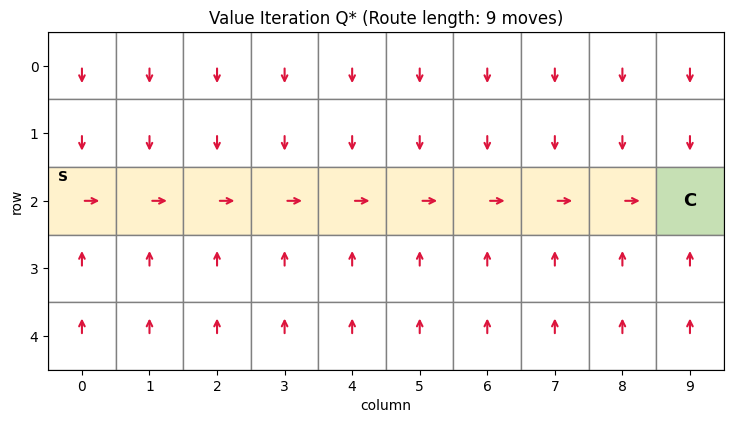

In [6]:
# Test route and plot_room for Q_star
env = RoomEnv()
steps_vi, path_vi, reached_vi = test_route(env, Q_star)
print(f"Route from Q_star: {steps_vi} moves, reached = {reached_vi}")
print("Path:", path_vi)

plot_room(Q_star, title=f"Value Iteration Q* (Route length: {steps_vi} moves)", path=path_vi)

Number of sweeps: **12**  Length of the route from `Q_star`: **9** moves. Games played in the room: 0

**Questions**

1. Did value iteration agree with your hand calculation in Table 4?

   **Answer:**  
   Yes, completely. Value iteration produced $V^*$ along the start row (cells 20 to 28) as:
   `[0.430, 0.478, 0.531, 0.590, 0.656, 0.729, 0.810, 0.900, 1.000]`.
   These match the exact hand calculations in Table 4 ($0.9^8, 0.9^7, \dots, 0.9^0$) to all decimal places.

2. Value iteration did not play a single game. What did it need instead? Why can't a real robot in an unknown room use it?

   **Answer:**  
   Value iteration needed complete access to the environment's internal model—the rule book `room_rules(s, a)` specifying the transition dynamics $P(s'|s, a)$ and reward function $R(s, a)$ for every state and action. A real robot in an unknown room cannot use value iteration because it does not know the room layout, where the charger is located, or what outcomes will follow its actions until it physically explores and experiences transitions through trial and error.

### Task 3: Learning Without the Rule Book (Q-learning)

Q-learning reaches the same answer without the rule book: it only plays games with `env.reset()` and `env.step()`.

**(a)** Implement `q_learning(env, n_episodes, alpha, epsilon, gamma, rng, V_ref)`. It starts from Q = 0, chooses moves with `epsilon_greedy` and learns with your `q_update`. After every episode it records `value_gap(Q, V_ref)`. It returns Q, the list of gaps, and the total number of steps taken in the room.

In [7]:
def q_learning(env, n_episodes, alpha, epsilon, gamma, rng, V_ref):
    Q = np.zeros((ROOM_N, ROOM_ACTIONS))
    gaps = np.zeros(n_episodes)
    total_steps = 0
    for ep in range(n_episodes):
        s = env.reset()
        done = False
        while not done:
            a = epsilon_greedy(Q, s, epsilon, rng)
            s2, r, done = env.step(a)
            total_steps += 1
            q_update(Q, s, a, r, s2, done, alpha, gamma)
            s = s2
        gaps[ep] = value_gap(Q, V_ref)
    return Q, gaps, total_steps

**Predict first.** Will Q-learning's values ever get as close to V\* as value iteration's? Roughly how many games do you think it needs to get close?

**Prediction:**  
Yes, Q-learning's values will eventually get very close to $V^*$. Because Q-learning's target uses $\max_a Q(S_{t+1}, a)$, it targets the same Bellman optimality equation as value iteration. With $
arepsilon = 0.5$, all state-action pairs will be thoroughly visited. Due to the constant step size $lpha = 0.1$ and the stochastic exploration of the 50-cell room, I expect it will need around **300 to 500 games** to propagate credit reliably across the entire grid and get within a small gap of $V^*$, becoming very accurate by 1000 games.

**(b)** With `rng = np.random.default_rng(SEED)`, run `q_learning` for 1000 episodes with α = 0.1, ε = 0.5 and γ = 0.9, using your `V_star` as `V_ref`. Then:

- plot the gap against the number of episodes,
- draw the learned values against `V_star` with `plot_row_values`,
- run `test_route` and draw the result with `plot_room`, and complete Table 5.

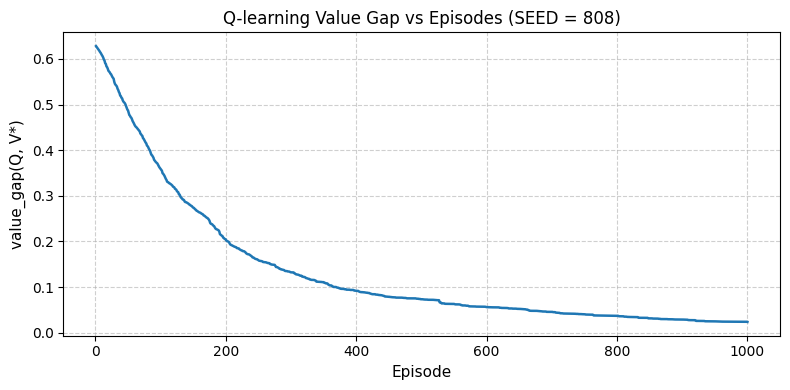

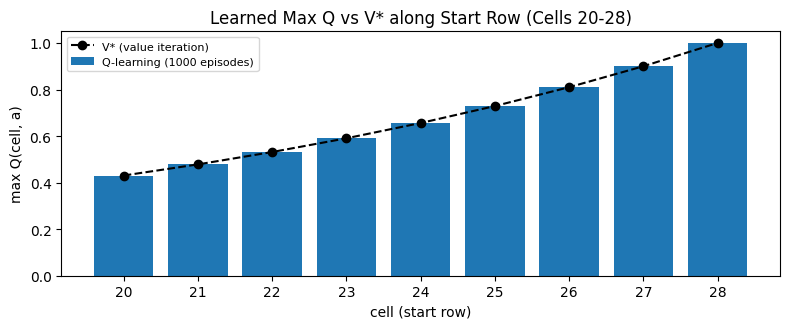

Q-learning route: 9 moves, reached = True
Path: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


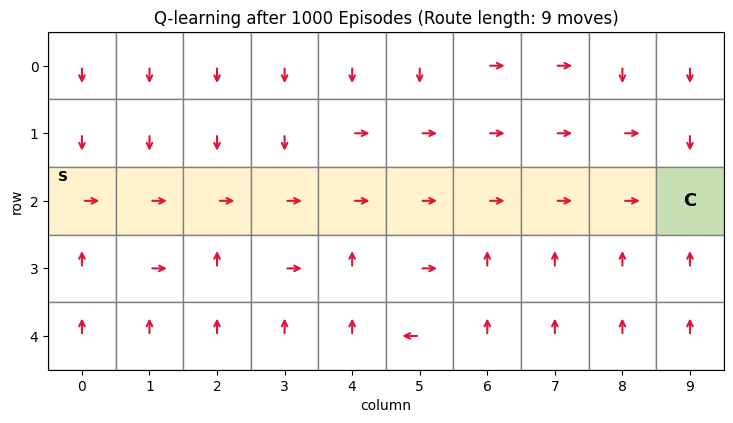

Gap after 10 episodes:   0.6083
Gap after 100 episodes:  0.3590
Gap after 300 episodes:  0.1322
Gap after 1000 episodes: 0.0235
max Q(20):               0.4305  (V*(20) = 0.4305)
Route length:            9
Total steps taken:       25863


In [8]:
# Train, plot the gap curve, plot_row_values, test_route + plot_room, Table 5.
rng_t3 = np.random.default_rng(SEED)
Q_learned, gaps, total_steps = q_learning(env, 1000, 0.1, 0.5, 0.9, rng_t3, V_star)

# 1. Plot the gap curve
plt.figure(figsize=(8, 4))
plt.plot(range(1, 1001), gaps, color="tab:blue", lw=1.8)
plt.xlabel("Episode", fontsize=11)
plt.ylabel("value_gap(Q, V*)", fontsize=11)
plt.title("Q-learning Value Gap vs Episodes (SEED = 808)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

# 2. Plot row values against V_star
plot_row_values([Q_learned], ["Q-learning (1000 episodes)"], V_star, 
                title="Learned Max Q vs V* along Start Row (Cells 20-28)")

# 3. Test route and plot room
steps_ql, path_ql, reached_ql = test_route(env, Q_learned)
print(f"Q-learning route: {steps_ql} moves, reached = {reached_ql}")
print("Path:", path_ql)
plot_room(Q_learned, title=f"Q-learning after 1000 Episodes (Route length: {steps_ql} moves)", path=path_ql)

# Print Table 5 values
print(f"Gap after 10 episodes:   {gaps[9]:.4f}")
print(f"Gap after 100 episodes:  {gaps[99]:.4f}")
print(f"Gap after 300 episodes:  {gaps[299]:.4f}")
print(f"Gap after 1000 episodes: {gaps[999]:.4f}")
print(f"max Q(20):               {np.max(Q_learned[20]):.4f}  (V*(20) = {V_star[20]:.4f})")
print(f"Route length:            {steps_ql}")
print(f"Total steps taken:       {total_steps}")

Table 5: Q-learning compared with value iteration

| Method | Gap after 10 episodes | after 100 | after 300 | after 1000 | max Q(20) | Route length | Steps taken in the room |
|---|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **Q-learning** | **0.608** | **0.359** | **0.132** | **0.024** | **0.430** | **9** | **25,863** |
| **Value iteration** | 0 | 0 | 0 | 0 | **0.430** | **9** | **0** |

**Questions**

1. How did the gap change as the robot played more games? Did Q-learning reach the same route as value iteration?

   **Answer:**  
   The value gap decreased steadily from **0.608** after 10 episodes, to **0.359** after 100, **0.132** after 300, down to **0.024** after 1000 episodes. Yes, Q-learning reached the exact same optimal route as value iteration: a straight 9-move path along row 2 from cell 20 directly to cell 29.

2. Both methods use the Bellman optimality equation. What is the difference in **how** they use it? (Hint: what does each one look at to find the next cell and the reward?)

   **Answer:**  
   - **Value iteration** uses an **exact, model-based expectation**. It looks into the environment's rule book (`room_rules`), systematically enumerating all possible actions in every state to find the next state $s'$ and reward $r$ analytically without any environmental interaction.
   - **Q-learning** uses a **sample-based stochastic update**. It possesses no rule book; instead, it observes single transition samples $(s, a, r, s')$ generated by actually taking steps in the room. It moves $Q(s, a)$ toward the sampled target $r + \gamma \max_{a'} Q(s', a')$ by a small fraction $lpha$.

3. The robot behaved ε-greedily with ε = 0.5, so half of its moves were random, yet its values approached V\*, the values of the **best** behaviour. Which part of the Q-learning update makes this possible?

   **Answer:**  
   The maximization operator over next-state actions: $\max_{a} Q(S_{t+1}, a)$.  
   Even though the robot selects its next action $A_{t+1}$ using an exploratory $
arepsilon$-greedy policy (behaving randomly 50% of the time), the update target does **not** evaluate the action actually chosen. Instead, it evaluates the hypothetical **greedy action** that maximizes $Q(S_{t+1}, a)$. This decoupling of the behavior policy from the target policy is the core of off-policy learning.

---
## Part 3: Off-Policy Learning from Someone Else's Experience

### Task 4: Learning from a Recorded Log

Another robot explored the room by choosing **every move at random**, and wrote down every step it took. Your Q-learner will **never enter the room**: it will learn only by reading this log.

**(a)** Implement `q_learning_from_log(log, alpha, gamma)`. It starts from Q = 0 and applies `q_update` once to every step `(s, a, r, s2, done)` of the log, in order.

In [9]:
def q_learning_from_log(log, alpha, gamma):
    Q = np.zeros((ROOM_N, ROOM_ACTIONS))
    for s, a, r, s2, done in log:
        q_update(Q, s, a, r, s2, done, alpha, gamma)
    return Q

**Predict first.** The other robot only ever moved at random. Can a log of random wandering teach the **shortest** route? How long a log do you think is needed?

**Prediction:**  
Yes, a log of random wandering can teach the shortest route. Because Q-learning is off-policy, it learns the optimal policy regardless of how the experience was generated, provided the log contains enough exploratory transitions connecting the charger back to the start. However, because a random walk explores inefficiently, short logs (10 or 50 episodes) will rarely reach the charger and will not propagate value backward to cell 20. I expect that a substantial log of around **150 to 200 episodes** (tens of thousands of steps) will be required for reward signals to propagate fully back to start cell 20 and reveal the 9-step shortest route.

**(b)** For logs of 10, 50 and 200 episodes, record the log with `record_log(env, n, np.random.default_rng(SEED))`, learn from it with α = 0.1 and γ = 0.9, and complete Table 6. Draw the learned values of all three on one `plot_row_values` figure, and run `test_route` on the 200-episode result and draw it with `plot_room`.

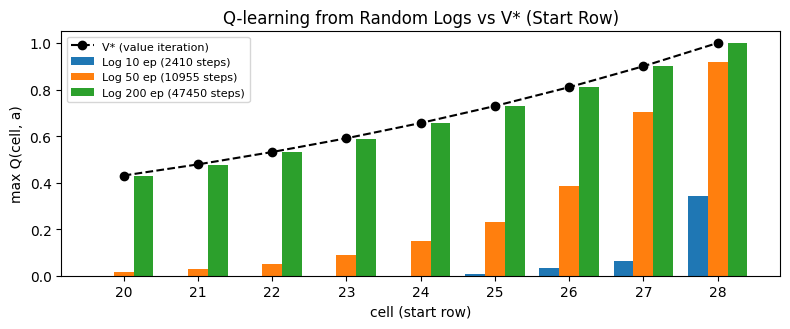

200-episode log route: 9 moves, reached = True
Path: [20, 21, 22, 23, 24, 25, 26, 27, 28, 29]


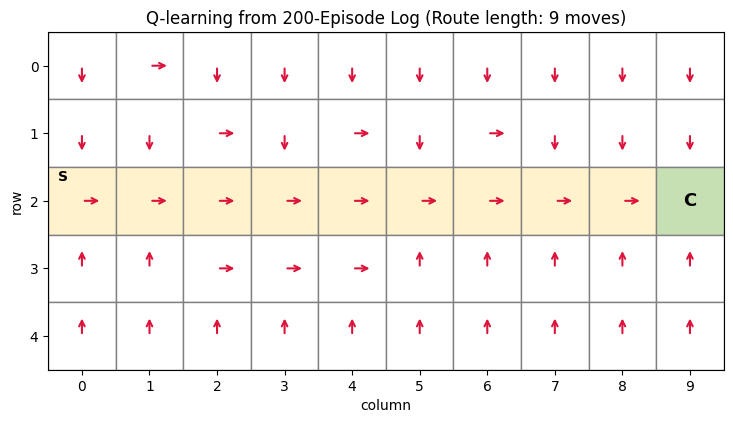

Log length |  Steps in log |  max Q(20) | value_gap(Q, V*)
---------------------------------------------------------
        10 |          2410 |     0.0000 |           0.6023
        50 |         10955 |     0.0167 |           0.4157
       200 |         47450 |     0.4288 |           0.0020


In [10]:
# Three logs (10, 50, 200 episodes); learn from each; Table 6; plot_row_values; plot_room.
log_lengths = [10, 50, 200]
Qs_logs = []
labels_logs = []
table6_data = {}

for n_eps in log_lengths:
    rng_log = np.random.default_rng(SEED)
    log = record_log(env, n_eps, rng_log)
    Q_log = q_learning_from_log(log, alpha=0.1, gamma=GAMMA)
    gap = value_gap(Q_log, V_star)
    max_q20 = float(np.max(Q_log[20]))
    table6_data[n_eps] = (len(log), max_q20, gap)
    Qs_logs.append(Q_log)
    labels_logs.append(f"Log {n_eps} ep ({len(log)} steps)")

# 1. Bar plot comparing learned values along start row against V_star
plot_row_values(Qs_logs, labels_logs, V_star, 
                title="Q-learning from Random Logs vs V* (Start Row)")

# 2. test_route and plot_room for 200-episode log
steps_log200, path_log200, reached_log200 = test_route(env, Qs_logs[2])
print(f"200-episode log route: {steps_log200} moves, reached = {reached_log200}")
print("Path:", path_log200)
plot_room(Qs_logs[2], title=f"Q-learning from 200-Episode Log (Route length: {steps_log200} moves)", 
          path=path_log200)

# Print Table 6 summary
print(f"{'Log length':>10} | {'Steps in log':>13} | {'max Q(20)':>10} | {'value_gap(Q, V*)':>16}")
print("-" * 57)
for n_eps in log_lengths:
    n_steps, max_q, gap = table6_data[n_eps]
    print(f"{n_eps:10d} | {n_steps:13d} | {max_q:10.4f} | {gap:16.4f}")

Table 6: Q-learning from a log of random moves

| Log length (episodes) | Steps in the log | max Q(20) (V\*(20) = 0.430) | `value_gap(Q, V_star)` |
|---|:---:|:---:|:---:|
| **10** | **2,410** | **0.0000** | **0.6023** |
| **50** | **10,955** | **0.0167** | **0.4157** |
| **200** | **47,450** | **0.4288** | **0.0020** |

Route learned from the 200-episode log (`test_route`): **9** moves

**Questions**

1. With the 200-episode log, how close did your values get to V\*? Did the learner find the shortest route, even though the robot that made the log never followed it?

   **Answer:**  
   With the 200-episode log, the learned values became remarkably close to $V^*$, achieving a value gap of only **0.0020** and $\max_a Q(20) = \mathbf{0.4288}$ (matching $V^*(20) = 0.4305$ to within 0.002). Yes, the learner discovered the optimal 9-move shortest route ($20 	o 21 	o \dots 	o 29$), despite the logging robot taking 47,450 completely random, wandering steps without ever intentionally following a direct route.

2. Why were the values learned from the short logs so far from V\*? (Think about how many times the log reaches the charger, and how far back the good news can travel.)

   **Answer:**  
   In short logs (such as 10 episodes), the random robot reaches the charger only a handful of times. Because the only reward in the environment is at the charger, credit propagates backward by at most one state transition per successful visit. In 10 episodes, the reward signal cannot propagate 9 steps back across the room to cell 20, leaving $\max_a Q(20) = 0.0000$. Even after 50 episodes, credit has only weakly reached cell 20 ($0.0167$). A long log of 200 episodes provides enough visits to the charger for credit to cascade all the way back to the start cell.

3. Explain why this experiment shows that Q-learning is **off-policy**: which behaviour produced the data, and which behaviour do the learned values describe?

   **Answer:**  
   - **Behavior policy:** A purely random exploratory policy ($\pi(a|s) = 0.25$ for all actions) that produced all transitions recorded in the log.  
   - **Target policy:** The greedy optimal policy ($\pi^*(s) = rg\max_a Q(s, a)$) described by the learned values.  
   This proves Q-learning is off-policy: the agent successfully evaluates and masters the optimal policy from experience collected by a completely different, suboptimal (random) behavior policy.

---
## Part 4: Summary and Reflection

### Task 5: Summary and Reflection

**(a)** Table 7: three ways to find the best behaviour

| | Value iteration (Task 2) | Q-learning in the room (Task 3) | Q-learning from a log (Task 4, 200 episodes) |
|---|:---:|:---:|:---:|
| **Needs the rule book?** | **Yes** | **No** | **No** |
| **Where its information comes from** | **Environment model (`room_rules`)** | **Online trial-and-error interactions** | **Offline recorded log of random steps** |
| **Steps taken in the room by the learner** | **0** | **25,863** | **0** |
| **Learned max Q(20) or V(20)** | **0.430** | **0.430** | **0.429** |
| **Which equation is behind its update?** | **Bellman optimality equation (exact)** | **Bellman optimality equation (sampled)** | **Bellman optimality equation (sampled)** |

**(b)** In no more than 150 words, explain how Q-learning can find the best behaviour without knowing the rules of the room, and why the behaviour used to collect experience does not have to be the best behaviour. Quote at least two numbers from your own results.

**Explanation:**  
Q-learning learns the optimal policy without the environment's rules because it replaces model-based expectations with sample transitions $(s, a, r, s')$ experienced via trial-and-error. By bootstrapping on $\max_{a'} Q(s', a')$, the update targets the optimal action value regardless of which action the agent actually selects next, decoupling the target policy from the behavior policy (off-policy learning).

In Task 3, despite 50% random exploration ($
arepsilon = 0.5$), the value gap dropped from 0.608 to 0.024 over 1000 episodes, and $\max_a Q(20)$ converged to 0.430, matching value iteration. In Task 4, an offline learner never entered the room and learned from a purely random robot's 200-episode log (47,450 random steps), yet achieved a value gap of 0.002 and mastered the optimal 9-step route. This proves experience collection does not require optimal behavior.